# 1. CONTOURS 

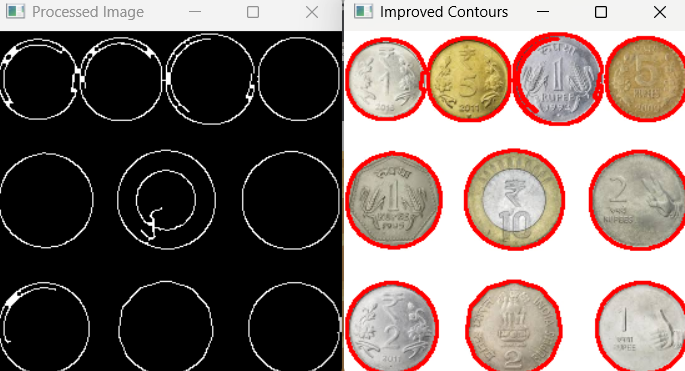

In [1]:
import cv2 as cv 

image=cv.imread("IMAGES/iphone2.png")
image=cv.resize(image , None , fx=0.5 , fy=0.5  , interpolation=cv.INTER_AREA)

gray=cv.cvtColor(image , cv.COLOR_BGR2GRAY)
blurred=cv.bilateralFilter(gray, 9 , 75 ,75)

edges=cv.Canny(blurred , 50 , 150 )
kernel=cv.getStructuringElement(cv.MORPH_RECT , (3,3))
closed_edges=cv.morphologyEx(edges , cv.MORPH_CLOSE , kernel)

contours , heirarchy = cv.findContours(closed_edges , cv.RETR_EXTERNAL , cv.CHAIN_APPROX_SIMPLE)

result = image.copy()

for cnt in contours:
    area=cv.contourArea(cnt)
    perimeter=cv.arcLength(cnt , True)
    print("PERIMETER: ", perimeter)
    if area > 20:
        cv.drawContours(result , [cnt] , -1 ,  (0,0,255),2)

cv.imshow("Processed Image" , closed_edges)
cv.imshow("Improved Contours", result)

cv.waitKey(0)
cv.destroyAllWindows()

PERIMETER:  59.597978472709656
PERIMETER:  1528.864128947258


# 2. BOUNDING BOXES

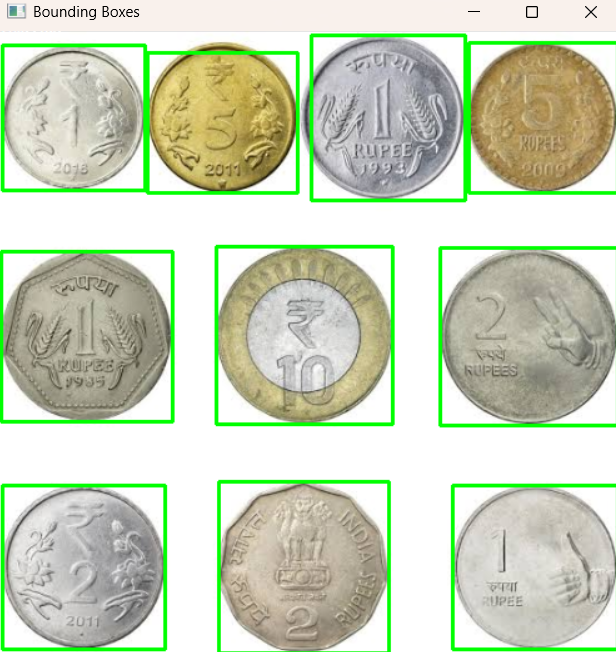

In [82]:
import cv2 as cv

image = cv.imread("IMAGES/coins.png")
image=cv.resize(image , None , fx=0.9 , fy=0.9  , interpolation=cv.INTER_AREA)

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
blurred=cv.bilateralFilter(gray ,9 , 75 , 75)

edges = cv.Canny(blurred, 50, 150)
kernel=cv.getStructuringElement(cv.MORPH_RECT , (3,3))
closed_edges=cv.morphologyEx(edges , cv.MORPH_CLOSE , kernel)

contours, hierarchy = cv.findContours(edges,cv.RETR_EXTERNAL,cv.CHAIN_APPROX_SIMPLE)

for contour in contours:

    area = cv.contourArea(contour)

    # Remove small contours
    if area > 55:

        x, y, w, h = cv.boundingRect(contour)

        cv.rectangle(image,(x, y),(x + w, y + h),(0, 255, 0),2)

cv.imshow("Bounding Boxes", image)

cv.waitKey(0)
cv.destroyAllWindows()

## 3.Shape Detection

In [43]:
import cv2 as cv
image=cv.resize(cv.imread("IMAGES/shapes.png") , None , fx=1 , fy=1 , interpolation=cv.INTER_AREA)

gray=cv.cvtColor(image , cv.COLOR_BGR2GRAY)
blurr=cv.bilateralFilter(gray,9,75,75)
edges=cv.Canny(blurr , 50,150)

kernel=cv.getStructuringElement(cv.MORPH_RECT , (3,3))
closed_edges=cv.morphologyEx(edges , cv.MORPH_CLOSE , kernel)


contours , heirarchy=cv.findContours(closed_edges,  cv.RETR_EXTERNAL , cv.CHAIN_APPROX_SIMPLE)
for contour in contours:
    perimeter = cv.arcLength(contour, True)

    approx = cv.approxPolyDP(
        contour, 0.01 * perimeter, True
    )

    vertices = len(approx)
    
    if vertices == 3:
        shape = "Triangle"

    elif vertices == 4:
        x, y, w, h = cv.boundingRect(approx)

        ratio = w / float(h)
        if 0.95 <= ratio <= 1.05:
            shape = "Square"
        else:
            shape = "Rectangle"

    elif vertices == 5:
        shape = "Pentagon"

    elif vertices == 6:
        shape = "Hexagon"

    else:
        shape = "Other"

    cv.drawContours(image, [approx], -1, (0, 255, 0), 2)

    x, y, w, h = cv.boundingRect(approx)
    cv.putText(
        image, shape, (x, max(y - 10, 20)),
        cv.FONT_HERSHEY_SIMPLEX, 0.6,
        (0, 0, 255), 2
    )

cv.imshow("Edges", edges)
cv.imshow("Shape Detection", image)

cv.waitKey(0)
cv.destroyAllWindows()

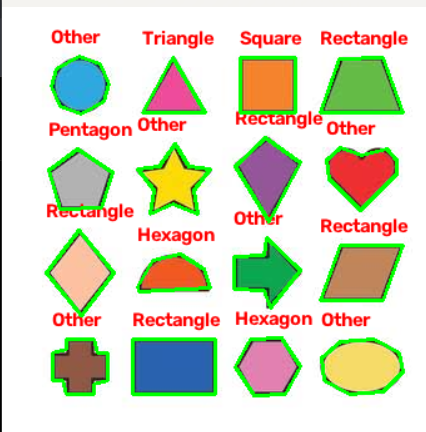

In [51]:

import cv2 as cv

image = cv.imread("IMAGES/shapes.png")
gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
edges = cv.Canny(cv.GaussianBlur(gray, (5, 5), 0), 50, 150)

contours, _ = cv.findContours(
    edges, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE
)

for cnt in contours:
    approx = cv.approxPolyDP(cnt, 0.02 * cv.arcLength(cnt, True), True)
    n = len(approx)

    if n == 3:
        shape = "Triangle"
    elif n == 4:
        x, y, w, h = cv.boundingRect(approx)
        shape = "Square" if 0.95 <= w / h <= 1.05 else "Rectangle"
    elif n == 5:
        shape = "Pentagon"
    elif n == 6:
        shape = "Hexagon"
    else:
        shape = "Other"

    x, y, w, h = cv.boundingRect(approx)
    cv.drawContours(image, [approx], -1, (0, 255, 0), 2)
    cv.putText(image, shape, (x, max(y - 10, 20)),
               cv.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

cv.imshow("Shape Detection", image)
cv.waitKey(0)
cv.destroyAllWindows()


In [ ]:
import cv2 as cv
import numpy as np

image = cv.imread("IMAGES/road2.png")

if image is None:
    raise FileNotFoundError("Image not found")

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
edges = cv.Canny(cv.GaussianBlur(gray, (5, 5), 0), 50, 150)

# Correct single call to HoughLinesP
lines = cv.HoughLinesP(
    edges, 
    rho=1, 
    theta=np.pi / 180,
    threshold=50,
    minLineLength=50,
    maxLineGap=10
)

if lines is not None:
    if lines is not None:
        for x1, y1, x2, y2 in np.asarray(lines).reshape(-1, 4):
            cv.line(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

cv.imshow("Edges", edges)
cv.imshow("Hough Lines", image)
cv.waitKey(0)
cv.destroyAllWindows()
